In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi 

In [3]:
prefix = '/mnt/staging/'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

data_root = str(FIGURES / "figureS2") + "/"

mouse='cm126'

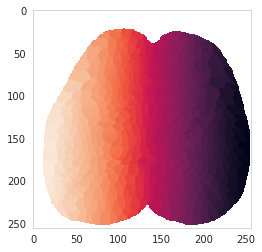

In [4]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
plt.imshow(IDX_sorted)

In [5]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


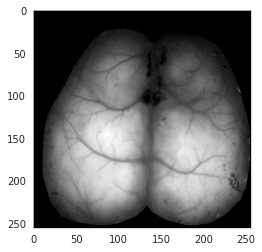

In [6]:
masked_brain = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain,0)
plt.imshow(masked_brain,cmap='gray',vmin=500,vmax=4500)

In [7]:

palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'
palatte_dict['mouth_M2']='#bf8fc9'
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#4b0082'
palatte_dict['RW_M2']=palatte_dict['LW']
palatte_dict['LatM']=palatte_dict['ALM']


In [8]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model


**load data**

In [9]:
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
all_ind = sensory_ind.copy()
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
all_ind.update(extra_ind)
sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']
sensory_ind['LM']=sensory_ind['mouth']
sensory_ind['RHP']=378
sensory_ind['RN']=495

In [10]:
choice_body_part_dict = {0:'RW',1:'RM_M2',2:'RFP_M2',3:'LatM'}

choice_dict = {0:sensory_ind['RW'],1:[],2:[],3:432}


In [11]:
behavior_colors = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488',
                  '#F39B7F', '#8491B4', '#91D1C2FF','#7E6148','#B09C85', '#DC0000'
                   ]

In [12]:
col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
col_list_palette = sns.xkcd_palette(col_list)

### load rest-running epochs

In [13]:
f = scipy.io.loadmat(data_root+'STIM_'+mouse+'_filt.mat',
)

M_jrgeco=f['M_jrgeco']
# M_jrgeco_std=f['M_jrgeco_std']
# M_chbt = f['M_chbt']
# M_chbt_std = f['M_chbt_std']
M_pupil_pc=f['M_pupil_pc']
M_face_pc=f['M_face_pc']
M_rotf = f['M_rotf']
M_rotf_raw = f['M_rotf_raw']
M_body_pc = f['M_body_pc']
M_whisk_vel = f['M_whisk_vel']
M_whisk_vel_norm = f['M_whisk_vel_norm']
M_nose_vel_norm=f['M_nose_vel_norm']
M_nose_vel = f['M_nose_vel']
M_LFP_vel=f['M_LFP_vel']
M_LFP_vel_norm=f['M_LFP_vel_norm']
M_RFP_vel=f['M_RFP_vel']
M_RFP_vel_norm=f['M_RFP_vel_norm']
M_pupil_pc_norm=f['M_pupil_pc_norm']
                            
# M_pupil_p_value=f['M_pupil_p_value']
M_day_label=np.squeeze(f['M_day_label'])
M_is_groom=f['M_is_groom']
M_y_rise_LFP_raw = f['M_y_rise_LFP_raw']
M_y_rise_LFP=f['M_y_rise_LFP']
M_ind=np.squeeze(f['M_ind'])
M_ind_stop=np.squeeze(f['M_ind_stop'])

M_mirrorRFP_vel = f['M_mirrorRFP_vel']
M_mirrorRFP_vel_norm = f['M_mirrorRFP_vel_norm']
M_mirrorLFP_vel = f['M_mirrorLFP_vel']
M_mirrorLFP_vel_norm = f['M_mirrorLFP_vel_norm']
M_mirrorRHP_vel = f['M_mirrorRHP_vel']
M_mirrorRHP_vel_norm = f['M_mirrorRHP_vel_norm']
M_mirrorLHP_vel = f['M_mirrorLHP_vel']
M_mirrorLHP_vel_norm = f['M_mirrorLHP_vel_norm']

T_PRE = 100
T_POST = 100
T = T_PRE+T_POST

for i,label in enumerate(M_day_label):
    M_day_label[i]=label.split(' ')[0]
    


## get full resolution data

In [14]:
# MM_jrgeco = np.empty((256,256,M_jrgeco.shape[1],0))
MM_jrgeco = []
for i_bout in range(M_jrgeco.shape[-1]): 
    session_id = M_day_label[i_bout]
    day = session_id.split(mouse+'_')[1].split('_')[0]
    run_id = session_id.split(mouse+'_')[1].split('_')[1]

    f3 = list(set(glob.glob(step_1_root+mouse+"/"+day+"/*"+run_id+"*.mat")))[0]
    ind = int(M_ind[i_bout]/3)

    with h5py.File(f3,'r') as f_H: 
        m = f_H['m']
        C = np.array(f_H['C']['jrgeco'])
        S = np.array(f_H['S']['jrgeco'])[ind-T_PRE:ind+T_POST,:]
        # cut [-60,60] frames slice
        # mask = np.array(f_H['mask'])
        # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
        nanidx = np.squeeze(m['nanidx'])==1
        CS = np.dot(S,C).transpose()
        jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
        jrgeco[:] = np.nan
        jrgeco[nanidx==True,:] = CS
        jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

    # MM_jrgeco = np.append(MM_jrgeco,jrgeco[:,:,:,np.newaxis],axis=3)
    MM_jrgeco.append(jrgeco)
    
MM_jrgeco = np.stack(MM_jrgeco, axis=-1)

**normalize**

In [15]:
behaviros_body_w_order = ['norm_M_mirrorRHP_vel_norm',
                     'norm_M_LFP_vel_norm','norm_M_RFP_vel_norm',
                     'norm_M_rotf']
behaviros_face_w_order = ['norm_M_whisk_vel_norm','norm_M_pupil_pc_norm','norm_M_face_pc']
palette_body=['#e97877','#0c4666','#adcee9','#f4c784']
palette_face=['#2A7377','#7B4EA1','#D15134','#BAB2AC','#2C5B78','#FFAE4E',]
# palette_face = [ '#DC63AA' ,'#232F17', '#D15134']
all_bev_short_dict={'norm_M_whisk_vel_norm':'whisk','norm_M_mirrorLHP_vel_norm':'mLHP','norm_M_mirrorRHP_vel_norm':'mRHP',
                     'norm_M_mirrorLFP_vel_norm':'mLFP','norm_M_mirrorRFP_vel_norm':'mRFP','norm_M_LFP_vel_norm':'LFP',
                      'norm_M_RFP_vel_norm':'RFP','norm_M_rotf':'rotary','norm_M_body_pc':'body PC','norm_M_face_pc':'face PC',
                    'norm_M_pupil_pc_norm':'pupil PC'}

In [16]:
for bev in all_bev_short_dict.keys():
    exec("{} = {} - np.mean({}[:T_PRE-40,:],0)[np.newaxis,:]".format(bev,bev[5:],bev[5:]))
    
norm_M_jrgeco = M_jrgeco - np.mean(M_jrgeco[:,:T_PRE-40,:],axis=1)[:,np.newaxis,:]
norm_MM_jrgeco = MM_jrgeco - np.mean(MM_jrgeco[:,:,:T_PRE-40,:],axis=2)[:,:,np.newaxis,:]  

In [17]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]

jrgeco2plot_M2 = {};node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    small_roi_tcs = np.nanmean(np.nanmean(
        norm_MM_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs
    
H_jrgeco_new_bsl=getH_4D(MM_jrgeco,IDX_sorted)

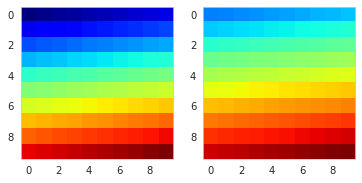

In [18]:
import matplotlib.colors as colors
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

arr = np.linspace(0, 50, 100).reshape((10, 10))
fig, ax = plt.subplots(ncols=2)

cmap = plt.get_cmap('jet')
new_cmap = truncate_colormap(cmap, 0.25, 1)
ax[0].imshow(arr, interpolation='nearest', cmap=cmap)
ax[1].imshow(arr, interpolation='nearest', cmap=new_cmap)
plt.show()

cmap = plt.get_cmap('jet')
new_cmap = truncate_colormap(cmap, 0.25, 1)

In [19]:
# zscore Delta_F/F 
norm_M_jrgeco_zscore = norm_M_jrgeco.copy()
norm_M_jrgeco_zscore = stats.zscore(norm_M_jrgeco_zscore,axis=1)
ss = norm_M_jrgeco.shape
norm_M_jrgeco_zscore_std = np.empty((ss[0],ss[1],0))
for i_bout in range(ss[2]):
    temp = pd.DataFrame(norm_M_jrgeco_zscore[:,:,i_bout]).T.rolling(20).std().T.values
    norm_M_jrgeco_zscore_std=np.append(norm_M_jrgeco_zscore_std,temp[:,:,np.newaxis],axis=2)

    


In [21]:
jrgeco2plot ={}
norm_jrgeco_zscored_std = {}
for i_bdp in range(4):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    if len(bdp.split('_'))==1:
        jrgeco2plot[bdp]=H_jrgeco_new_bsl[ind,:,:]
        norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
    else:
        if bdp.split('_')[1] == 'M2':
            jrgeco2plot[bdp] = jrgeco2plot_M2[bdp.split('_')[0]]
            norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
        else:
            jrgeco2plot[bdp] = H_jrgeco_new_bsl[ind,:,:] # RFP M1
            norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values


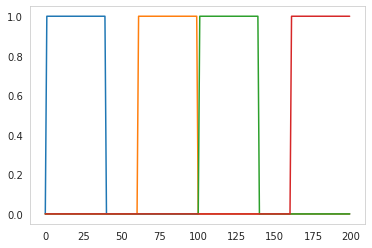

In [22]:
T = norm_M_body_pc.shape[0]
t_ax = np.divide(range(-T_PRE,T-T_PRE),20)

win1 = np.logical_and(t_ax>-5,t_ax<-3)
win2 = np.logical_and(t_ax>-2,t_ax<-0)
win3 = np.logical_and(t_ax>0,t_ax<2)
win4 = np.logical_and(t_ax>3,t_ax<5)


plt.plot(win1)
plt.plot(win2)
plt.plot(win3)
plt.plot(win4)
# plt.xlim([290,300])|

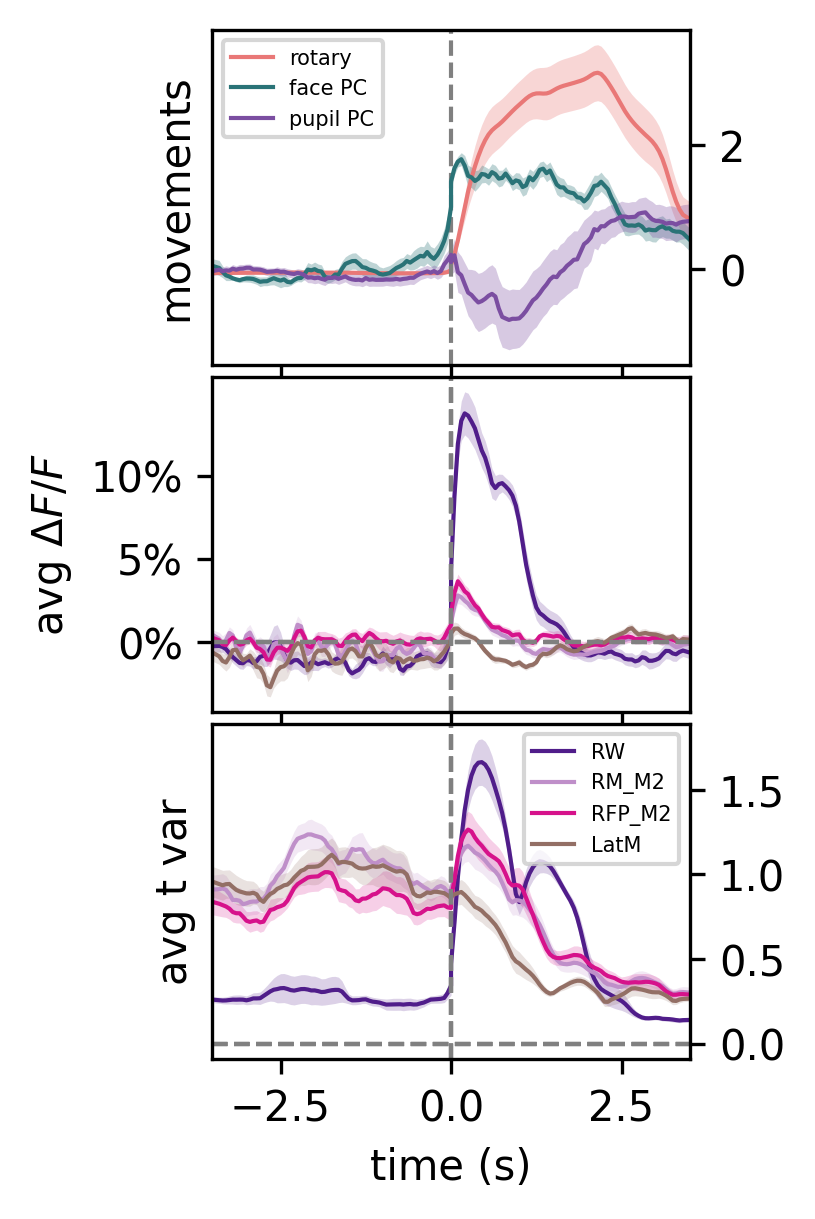

In [24]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;x_width=5

# behavior (body and facial movements)
x_start = x_offset 
x_stop = x_start+7
y_start = y_offset 
y_stop = y_start+5
for i_ax in range(0,3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop
    y_stop = y_start+5
    if i_ax < 2:
        exec("ax{}.set_xticklabels([])".format(i_ax)) 
    
# ax3 = fig.add_subplot(gs[y_start:y_start+1,x_start:x_stop])
# ax3.set_yticks([])

########################################
########################################

t_frame_trimmed = np.linspace(-70,70,140).astype('int')
t_ax_trimmed = np.divide(t_frame_trimmed,20)

# ampltitude
for i_bdp in range(4):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    data2plot = jrgeco2plot[bdp][T_PRE-70:T_PRE+70,:]
    
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax1.plot(t_ax_trimmed,avg,color=palatte_dict[bdp],label=bdp,linewidth=1)
    ax1.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp],alpha=0.2,linewidth=0)
    ax1.axvline(0,linewidth=1,linestyle='dashed',color='gray')
    ax1.axhline(0,linewidth=1,linestyle='dashed',color='gray')
    ax1.set_yticks([0,0.05,0.1])
    vals = ax1.get_yticks()
    ax1.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
    ax1.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax2.set_yticklabels([])

    
for i_bdp in range(4):
    bdp = choice_body_part_dict[i_bdp]
    
    ind = choice_dict[i_bdp]
    data2plot = norm_jrgeco_zscored_std[bdp][T_PRE-70:T_PRE+70,:]
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax2.plot(t_ax_trimmed,avg,color=palatte_dict[bdp],label=bdp,linewidth=1)
    ax2.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp],alpha=0.2,linewidth=0)
    ax2.axvline(0,linewidth=1,linestyle='dashed',color='gray')
    # ax1.set_yticks([-0.2,0,0.02])
    ax2.axhline(0,linewidth=1,linestyle='dashed',color='gray')
    ax2.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax1.set_xticklabels([])


    
# NOW plot behavior
# body movements

behaviros_body_w_order = [
                     'norm_M_rotf']
behaviros_face_w_order = ['norm_M_face_pc','norm_M_pupil_pc_norm']

all_bev_short_dict={'norm_M_whisk_vel_norm':'whisk','norm_M_mirrorLHP_vel_norm':'mLHP','norm_M_mirrorRHP_vel_norm':'mRHP',
                     'norm_M_mirrorLFP_vel_norm':'mLFP','norm_M_mirrorRFP_vel_norm':'mRFP','norm_M_LFP_vel_norm':'LFP',
                      'norm_M_RFP_vel_norm':'RFP','norm_M_rotf':'rotary','norm_M_body_pc':'body PC','norm_M_face_pc':'face PC',
                    'norm_M_pupil_pc_norm':'pupil PC'}
for i_behavior,behavior in enumerate(behaviros_body_w_order):
    exec("beh2plot = {}[T_PRE-70:T_PRE+70,:]".format(behavior))
    avg = np.mean(beh2plot,axis=1)#+i_behavior*2.5
    sem = stats.sem(beh2plot,axis=1)
    ax0.plot(t_ax_trimmed,avg,color=palette_body[i_behavior],linewidth=1,label=all_bev_short_dict[behavior])
    ax0.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palette_body[i_behavior],alpha=0.3,linewidth=0)
    ax0.set_xlim(np.divide([-70,70],20))
    # ax2.text(t_ax[0]+0.3,i_behavior*2.5+0.35,all_bev_short_dict[behavior],color=behavior_colors[i_behavior],fontsize=10)


ax0.axvline(0,linewidth=1,linestyle='dashed',color='gray')
  



for i_behavior,behavior in enumerate(behaviros_face_w_order):
    exec("beh2plot = {}[T_PRE-70:T_PRE+70,:]".format(behavior))
    avg = np.mean(beh2plot,axis=1)#+i_behavior*2.5
    sem = stats.sem(beh2plot,axis=1)
    ax0.plot(t_ax_trimmed,avg,color=palette_face[i_behavior],linewidth=1,label=all_bev_short_dict[behavior])
    ax0.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palette_face[i_behavior],alpha=0.3,linewidth=0)
    ax0.set_xlim(np.divide([-70,70],20))
    # ax2.text(t_ax[0]+0.3,i_behavior*2.5+0.35,all_bev_short_dict[behavior],color=behavior_colors[i_behavior],fontsize=10)


# for i_win,win in enumerate(['win1','win2','win3','win4']):
#     exec("win_here = {}[T_PRE-100:T_PRE+100]".format(win))
#     ax3.vlines(t_ax_trimmed[np.where(win_here==True)], 0, 0.5,linewidth=1,color=sns.color_palette("Set2")[i_win])
#     ax3.vlines(0, 8, 9,linewidth=10,color=sns.color_palette("Set2")[i_win],label=win_here)#for the legend
# ax3.set_ylim([0,0.5])
    
    
####
ax0.legend(fontsize=5)
ax2.legend(fontsize=5)
# ax2.legend(fontsize=5)
ax1.set_ylabel('avg $\Delta F/F$')
ax2.set_ylabel('avg t var')
ax0.set_ylabel('movements');  
ax2.set_xlabel('time (s)')

ax0.yaxis.tick_right()
ax2.yaxis.tick_right()
###
# plt.savefig('figS2-stim-whisker-cm126.svg',format='svg',dpi=300)

In [25]:
all_gathered = ['norm_M_jrgeco','norm_MM_jrgeco','norm_M_jrgeco_zscore_std','T_PRE'] +list(all_bev_short_dict.keys())
all_gathered_dict = {key:[] for key in all_gathered}
for key in all_gathered_dict:
    exec("all_gathered_dict[key] = {}".format(key))
    
all_gathered_dict['jrgeco2plot']=jrgeco2plot
all_gathered_dict['norm_jrgeco_zscored_std']=norm_jrgeco_zscored_std

In [ ]:
save_pickle(all_gathered_dict,data_root+'STIM_'+mouse+'_final')
